# Spin-chain ground state

## Table of contents


- [Setup](#Setup)
- [Single run](#Single-run)
- [Seed sweep](#Seed-sweep)
- [Seed sweep with gradient noise](#Seed-sweep-with-gradient-noise)
- [Energy distribution at iteration 50](#Energy-distribution-at-iteration-50)
- [Sweep over h/J ratio: minimum energy across 50 seeds](#Sweep-over-h-J-ratio:-minimum-energy-across-50-seeds)
- [Exact solution](#Exact-solution)
  - [Comparison with the RBM](#Comparison-with-the-RBM)


- [Correctness check](#Correctness-check)
- [MCMC vs ED benchmark](#MCMC-vs-ED-benchmark)
- [Finer seed sweep and h/J sweep](#Finer-seed-sweep-and-h-J-sweep)

# Legacy (`NQS.py`, single-chain sampler)

### Setup

In [1]:
from NQS import *
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
rbm = RBM(
    num_visible=4,
    num_hidden=8,
    seed=0
)

tfi = TFI(
    N=4,
    J=1.0,
    h=2.0
)

mcmc = MCMC(
    n_spins=4,
    seed=1
)

vmc = VMC(
    rbm,
    tfi,
    mcmc
)

sr = SR(
    learning_rate=0.01,
    lambda_reg=1e-3
)

MCMC
  ↓
samples S₁, S₂, ..., Sₖ
  ↓
calculate E_loc(S)
  ↓
calculate O_i(S) = ∂ log ψ / ∂θ_i
  ↓
calculate gradient g
  ↓
calculate FB metric S
  ↓
solve (S + λI) Δθ = -ηg
  ↓
update v, h, W
  ↓
repeat

### Single run

In [3]:
energy_history = []
for iteration in range(50):

    # sample configurations
    samples = mcmc.sample(
        rbm,
        n_samples=1000,
        burn_in=100
    )

    # calculate local energies
    local_energies = torch.stack([
        vmc.local_energy(s.unsqueeze(0))
        for s in samples
    ]).squeeze()

    # update weights and biases
    sr.update(
        rbm,
        samples,
        local_energies
    )

    # Energy estimate
    energy = local_energies.mean()

    print(
        f"Iteration {iteration}: "
        f"E = {energy.item():.6f}"
    )

    energy_history.append(energy.item())

Iteration 0: E = -3.895736


Iteration 1: E = -5.274753


Iteration 2: E = -5.136678


Iteration 3: E = -5.922869


Iteration 4: E = -6.530567


...

Iteration 45: E = -8.501400


Iteration 46: E = -8.521688


Iteration 47: E = -8.504828


Iteration 48: E = -8.516076


Iteration 49: E = -8.519528


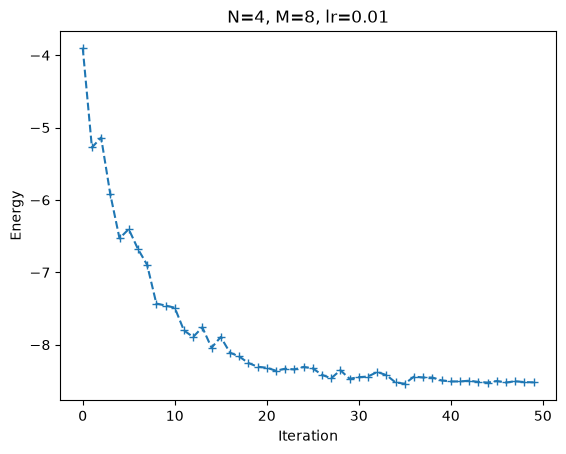

In [4]:
fig = plt.figure()
plt.plot(range(50), energy_history, marker='+', linestyle='--')
plt.xlabel('Iteration')
plt.ylabel('Energy')
plt.title(f'N={rbm.N}, M={rbm.M}, lr={sr.learning_rate}')
plt.show()

### Seed sweep

In [5]:
# Important note: num_visible corresponds to number of spins in the TFI chain.

def minimise_e(seed, n_iterations=50, n_samples=200, burn_in=50,
                            num_visible=4, num_hidden=8, J=1.0, h=2.0,
                            noise_std=0.0, reject_negative_energies=False):
    rbm = RBM(num_visible=num_visible, num_hidden=num_hidden, seed=seed)
    tfi = TFI(N=num_visible, J=J, h=h)
    mcmc = MCMC(n_spins=num_visible, seed=seed + 1_000_000)
    vmc = VMC(rbm, tfi, mcmc)
    sr = SR(learning_rate=0.01, lambda_reg=1e-3, noise_std=noise_std)

    # reject_negative_energies=True: reject negative energies by carrying
    # forward the last accepted (positive) value. If no positive value has
    # been seen yet, record NaN rather than forcing an early negative value
    # through - some (J, h) regimes never produce a positive raw energy at
    # all, and forcing that value through would silently defeat the
    # rejection filter.
    # reject_negative_energies=False (default): negative energies are
    # considered valid and appended as-is. This is the correct default now
    # that NQS.py's Hamiltonian sign bug is fixed -- true ground-state
    # energies are negative, so with reject_negative_energies=True every
    # correctly-converged run would be filtered out (see the note at the
    # top of this notebook).
    energy_history = []
    last_accepted = None
    for iteration in range(n_iterations):
        samples = mcmc.sample(rbm, n_samples=n_samples, burn_in=burn_in)
        local_energies = torch.stack([
            vmc.local_energy(s.unsqueeze(0)) for s in samples
        ]).squeeze()
        sr.update(rbm, samples, local_energies)
        energy = local_energies.mean().item()

        if not reject_negative_energies or energy > 0:
            last_accepted = energy
            energy_history.append(energy)
        elif last_accepted is not None:
            energy_history.append(last_accepted)
        else:
            energy_history.append(float('nan'))

    return energy_history


def run_seed(seed, **kwargs):
    return minimise_e(seed, **kwargs)[-1]


n_seeds = 50
seed_energies = [run_seed(seed) for seed in range(n_seeds)]

In [6]:
seed_energies_arr = np.array(seed_energies)
n_nan = np.isnan(seed_energies_arr).sum()

stats_table = pd.DataFrame({
    "Statistic": ["Mean", "Min", "Max", "Variance", "Excluded (NaN) seeds"],
    "Energy (iteration 50)": [
        np.nanmean(seed_energies_arr),
        np.nanmin(seed_energies_arr),
        np.nanmax(seed_energies_arr),
        np.nanvar(seed_energies_arr),
        n_nan,
    ],
})
stats_table

,Statistic,Energy (iteration 50)
0,Mean,-8.174192
1,Min,-8.586749
2,Max,-4.894855
3,Variance,0.595260
4,Excluded (NaN) seeds,0.000000


### Seed sweep with gradient noise

 `delta_theta = -eta * S_lambda^-1 * g + epsilon`, with
`epsilon_i ~ N(0, sigma^2)`.

 `noise_std=0.01`.

In [7]:
noise_std = 0.01
seed_energies_noisy = [
    run_seed(seed, noise_std=noise_std) for seed in range(n_seeds)
]

In [8]:
seed_energies_noisy_arr = np.array(seed_energies_noisy)
n_nan_noisy = np.isnan(seed_energies_noisy_arr).sum()

stats_table_noisy = pd.DataFrame({
    "Statistic": ["Mean", "Min", "Max", "Variance", "Excluded (NaN) seeds"],
    "Energy (iteration 50)": [
        np.nanmean(seed_energies_noisy_arr),
        np.nanmin(seed_energies_noisy_arr),
        np.nanmax(seed_energies_noisy_arr),
        np.nanvar(seed_energies_noisy_arr),
        n_nan_noisy,
    ],
})
stats_table_noisy

,Statistic,Energy (iteration 50)
0,Mean,-8.066908
1,Min,-8.661932
2,Max,-5.772355
3,Variance,0.521231
4,Excluded (NaN) seeds,0.000000


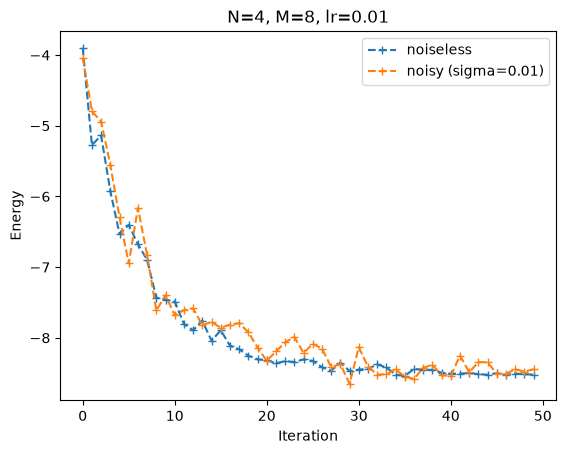

In [9]:
# Single-seed trajectory with noise, for comparison against the noiseless run above
noisy_history_demo = minimise_e(seed=0, noise_std=noise_std)

fig = plt.figure()
plt.plot(energy_history, marker='+', linestyle='--', label='noiseless')
plt.plot(noisy_history_demo, marker='+', linestyle='--', label=f'noisy (sigma={noise_std})')
plt.xlabel('Iteration')
plt.ylabel('Energy')
plt.title(f'N={rbm.N}, M={rbm.M}, lr={sr.learning_rate}')
plt.legend()
plt.show()

### Energy distribution at iteration 50

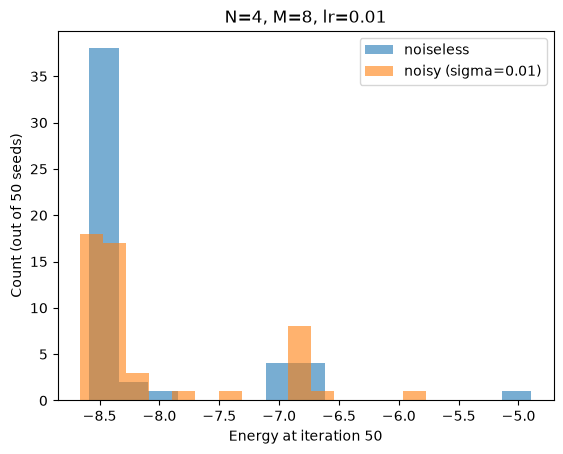

In [10]:
# Distribution of final (iteration-50) energies across the 50 seeds, noiseless vs noisy
# (NaN entries, if any, are excluded)
fig = plt.figure()
plt.hist(seed_energies_arr[~np.isnan(seed_energies_arr)], bins=15, alpha=0.6, label='noiseless')
plt.hist(seed_energies_noisy_arr[~np.isnan(seed_energies_noisy_arr)], bins=15, alpha=0.6, label=f'noisy (sigma={noise_std})')
plt.xlabel('Energy at iteration 50')
plt.ylabel('Count (out of 50 seeds)')
plt.title(f'N={rbm.N}, M={rbm.M}, lr={sr.learning_rate}')
plt.legend()
plt.show()

### Sweep over h/J ratio: minimum energy across 50 seeds

For fixed `J=1.0`, sweep the transverse-field ratio `h/J`; record minimum energy

In [11]:
J_fixed = 1.0
ratios = [0.1, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0]
sweep_settings = dict(n_iterations=20, n_samples=100, burn_in=20)

min_energy_noiseless = []
min_energy_noisy = []

for ratio in ratios:
    h = ratio * J_fixed

    energies_noiseless = np.array([
        run_seed(seed, J=J_fixed, h=h, **sweep_settings)
        for seed in range(n_seeds)
    ])
    energies_noisy = np.array([
        run_seed(seed, J=J_fixed, h=h, noise_std=noise_std, **sweep_settings)
        for seed in range(n_seeds)
    ])

    min_energy_noiseless.append(np.nanmin(energies_noiseless))
    min_energy_noisy.append(np.nanmin(energies_noisy))

    print(f"h/J = {ratio}: min(noiseless) = {min_energy_noiseless[-1]:.6f} "
          f"({np.isnan(energies_noiseless).sum()} NaN seeds), "
          f"min(noisy) = {min_energy_noisy[-1]:.6f} "
          f"({np.isnan(energies_noisy).sum()} NaN seeds)")

h/J = 0.1: min(noiseless) = -4.061078 (0 NaN seeds), min(noisy) = -4.052414 (0 NaN seeds)


h/J = 0.25: min(noiseless) = -4.162027 (0 NaN seeds), min(noisy) = -4.145618 (0 NaN seeds)


h/J = 0.5: min(noiseless) = -4.343956 (0 NaN seeds), min(noisy) = -4.439192 (0 NaN seeds)


h/J = 0.75: min(noiseless) = -4.602386 (0 NaN seeds), min(noisy) = -4.821319 (0 NaN seeds)


h/J = 1.0: min(noiseless) = -5.105484 (0 NaN seeds), min(noisy) = -5.222612 (0 NaN seeds)


...

h/J = 2.0: min(noiseless) = -8.767937 (0 NaN seeds), min(noisy) = -8.795145 (0 NaN seeds)


h/J = 3.0: min(noiseless) = -12.466515 (0 NaN seeds), min(noisy) = -12.482287 (0 NaN seeds)


h/J = 5.0: min(noiseless) = -20.365137 (0 NaN seeds), min(noisy) = -20.409458 (0 NaN seeds)


h/J = 7.0: min(noiseless) = -28.366558 (0 NaN seeds), min(noisy) = -28.251318 (0 NaN seeds)


h/J = 10.0: min(noiseless) = -40.161415 (0 NaN seeds), min(noisy) = -40.530224 (0 NaN seeds)


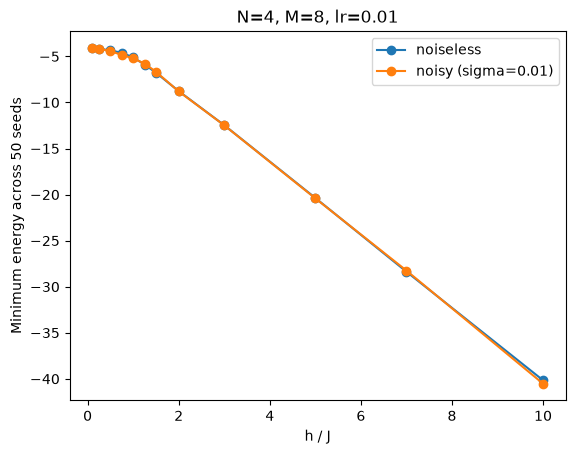

In [12]:
fig = plt.figure()
plt.plot(ratios, min_energy_noiseless, marker='o', linestyle='-', label='noiseless')
plt.plot(ratios, min_energy_noisy, marker='o', linestyle='-', label=f'noisy (sigma={noise_std})')
plt.xlabel('h / J')
plt.ylabel('Minimum energy across 50 seeds')
plt.title(f'N={rbm.N}, M={rbm.M}, lr={sr.learning_rate}')
plt.legend()
plt.show()

### Exact solution

Build every $H_{ij}=\left<s_i\right|H\left|s_j\right>$ for
$H=-J\sum_i\sigma^z_i\sigma^z_{i+1}-h\sum_i\sigma^x_i$ (periodic) and diagonalise.

In [13]:
from itertools import product

def ed_ground(N, J, h):
    basis = list(product([1, -1], repeat=N))
    index = {s: i for i, s in enumerate(basis)}

    H = np.zeros((2**N, 2**N))
    for j, s in enumerate(basis):
        # sigma^z sigma^z, diagonal
        H[j, j] = -J * sum(s[i] * s[(i+1) % N] for i in range(N))
        # sigma^x, flips one spin
        for i in range(N):
            flipped = list(s)
            flipped[i] *= -1
            H[index[tuple(flipped)], j] -= h

    return np.linalg.eigvalsh(H)[0]

E_exact = ed_ground(rbm.N, tfi.J, tfi.h)
print('Ground state energy:', E_exact)

# check against Table 6.1 of nqs_book.pdf
print('N=6, J=h=1:', ed_ground(6, 1.0, 1.0), '(book: -7.72740661)')

Ground state energy: -8.54311682027943
N=6, J=h=1: -7.727406610312556 (book: -7.72740661)


#### Comparison with the RBM

$\left<E_\text{loc}\right>\ge E_0$, so the variational energy should come down to the exact
line from above.

In [14]:
E_rbm = energy_history[-1]

print('exact    E_0 = %.6f' % E_exact)
print('RBM      <E> = %.6f' % E_rbm)
print('error        = %.6f  (%.1f %%)' % (E_rbm - E_exact, 100 * abs(E_rbm - E_exact) / abs(E_exact)))

exact    E_0 = -8.543117
RBM      <E> = -8.519528
error        = 0.023588  (0.3 %)


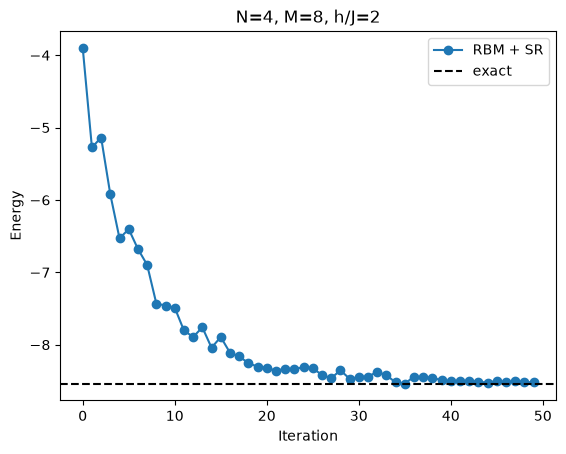

In [15]:
fig = plt.figure()
plt.plot(energy_history, marker='o', linestyle='-', label='RBM + SR')
plt.axhline(E_exact, color='k', linestyle='--', label='exact')
plt.xlabel('Iteration')
plt.ylabel('Energy')
plt.title(f'N={rbm.N}, M={rbm.M}, h/J={tfi.h/tfi.J:g}')
plt.legend()
plt.show()

# Optimized (`NQS_hpc.py`, batched multi-chain sampler)

Same physics, rewritten for batched execution and device-agnostic (CPU/GPU) operation — see
`spin_chain_ground_hpc.ipynb` for the large-`N`, GPU-oriented version meant to run on
Cambridge HPC (CSD3). This section stays at small/medium `N` so it runs comfortably on a
laptop, CPU only.

In [16]:
import time as _time

from NQS_hpc import ed_ground as ed_ground_hpc, run_training

DEVICE = "cpu"  # this notebook is the non-HPC, CPU-only version


## Correctness check

Same `N=4, M=8, J=1, h=2` setup as the legacy run above.

exact    E_0 = -8.543117
VMC      <E> = -8.539959
error        = 0.003158  (0.04 %)


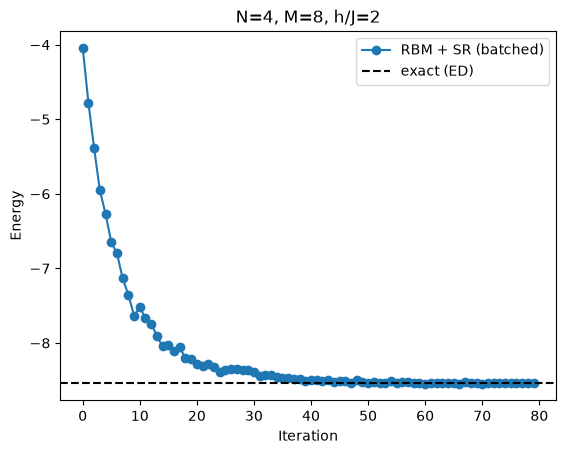

In [17]:
rbm_opt, energy_history_opt = run_training(
    N=4, M=8, J=1.0, h=2.0, seed=0,
    n_chains=64, n_steps=50, burn_in=100, n_iterations=80,
    device=DEVICE,
)

E_exact_opt = ed_ground_hpc(4, 1.0, 2.0)
E_vmc_opt = energy_history_opt[-1]

print(f"exact    E_0 = {E_exact_opt:.6f}")
print(f"VMC      <E> = {E_vmc_opt:.6f}")
print(f"error        = {E_vmc_opt - E_exact_opt:.6f}  ({100 * abs(E_vmc_opt - E_exact_opt) / abs(E_exact_opt):.2f} %)")

fig = plt.figure()
plt.plot(energy_history_opt, marker='o', linestyle='-', label='RBM + SR (batched)')
plt.axhline(E_exact_opt, color='k', linestyle='--', label='exact (ED)')
plt.xlabel('Iteration')
plt.ylabel('Energy')
plt.title(f'N={rbm_opt.N}, M={rbm_opt.M}, h/J={2.0/1.0:g}')
plt.legend()
plt.show()

## MCMC vs ED benchmark

Validation at small `N` (where exact diagonalization is tractable): the optimized sampler's
VMC energy plotted directly against the exact ground-state energy, across two sweeps.

### Energy vs `h/J`, for several fixed `N`

In [18]:
def train_final_energy(N, M, J, h, seed, n_iterations=60, n_chains=64, n_steps=60, burn_in=60):
    _, hist = run_training(
        N=N, M=M, J=J, h=h, seed=seed,
        n_chains=n_chains, n_steps=n_steps, burn_in=burn_in,
        n_iterations=n_iterations, device=DEVICE,
    )
    # average the last few iterations to damp sampling noise in the reported energy
    return float(np.mean(hist[-5:]))


Ns_for_ratio_sweep = [4, 6, 8, 10]
ratios_opt = np.linspace(0.1, 4.0, 30)
J_fixed_opt = 1.0

ratio_results = {N: {"mcmc": [], "ed": []} for N in Ns_for_ratio_sweep}

for N in Ns_for_ratio_sweep:
    M = 2 * N
    for ratio in ratios_opt:
        h = ratio * J_fixed_opt
        ratio_results[N]["mcmc"].append(train_final_energy(N, M, J_fixed_opt, h, seed=0, n_iterations=40, n_steps=40, burn_in=40))
        ratio_results[N]["ed"].append(ed_ground_hpc(N, J_fixed_opt, h))
    print(f"N={N} done")

N=4 done


N=6 done


N=8 done


N=10 done


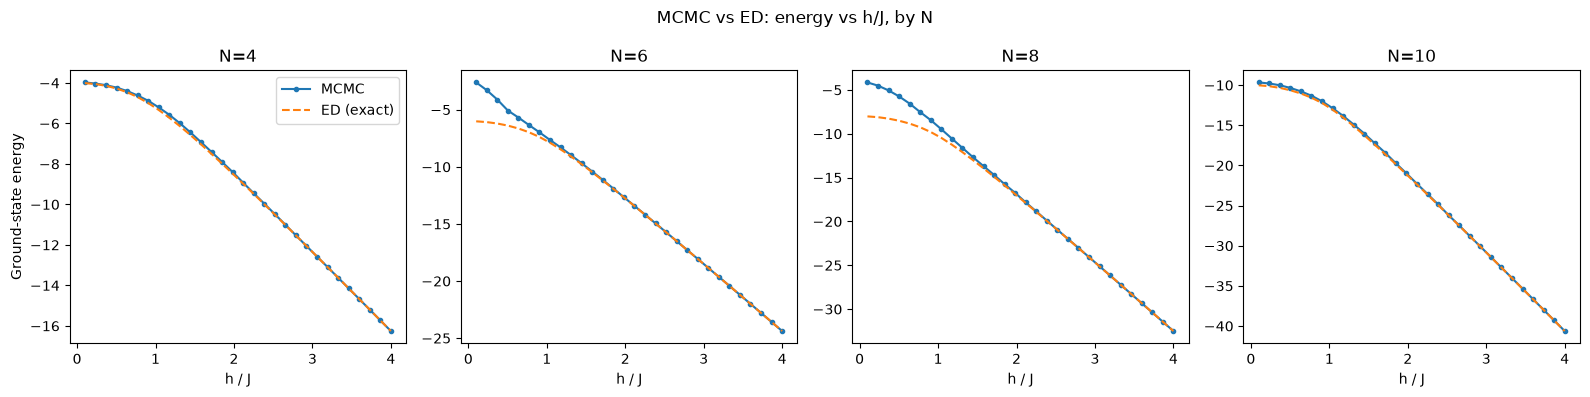

In [19]:
fig, axes = plt.subplots(1, len(Ns_for_ratio_sweep), figsize=(4 * len(Ns_for_ratio_sweep), 4), sharex=True)

for ax, N in zip(axes, Ns_for_ratio_sweep):
    ax.plot(ratios_opt, ratio_results[N]["mcmc"], label="MCMC", marker='o', markersize=3, linestyle='-')
    ax.plot(ratios_opt, ratio_results[N]["ed"], label="ED (exact)", linestyle='--')
    ax.set_title(f"N={N}")
    ax.set_xlabel("h / J")

axes[0].set_ylabel("Ground-state energy")
axes[0].legend()
fig.suptitle("MCMC vs ED: energy vs h/J, by N")
plt.tight_layout()
plt.show()

### Energy vs `N`, at fixed `h/J`

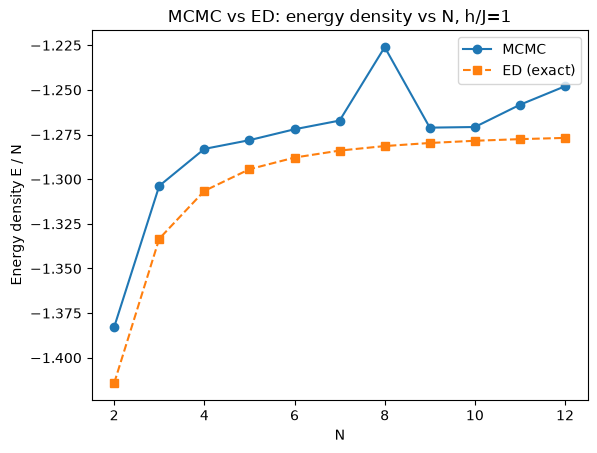

In [20]:
Ns_for_N_sweep = list(range(2, 13))
h_over_J_fixed = 1.0

n_sweep_mcmc = []
n_sweep_ed = []

for N in Ns_for_N_sweep:
    M = 2 * N
    h = h_over_J_fixed * J_fixed_opt
    n_sweep_mcmc.append(train_final_energy(N, M, J_fixed_opt, h, seed=0) / N)
    n_sweep_ed.append(ed_ground_hpc(N, J_fixed_opt, h) / N)

fig = plt.figure()
plt.plot(Ns_for_N_sweep, n_sweep_mcmc, marker='o', linestyle='-', label='MCMC')
plt.plot(Ns_for_N_sweep, n_sweep_ed, marker='s', linestyle='--', label='ED (exact)')
plt.xlabel('N')
plt.ylabel('Energy density E / N')
plt.title(f'MCMC vs ED: energy density vs N, h/J={h_over_J_fixed:g}')
plt.legend()
plt.show()

## Finer seed sweep and `h/J` sweep



In [21]:
def minimise_e_opt(seed, n_iterations=50, n_samples_steps=50, burn_in=50,
                    N=4, M=8, J=1.0, h=2.0, noise_std=0.0):
    _, hist = run_training(
        N=N, M=M, J=J, h=h, seed=seed,
        n_chains=64, n_steps=n_samples_steps, burn_in=burn_in,
        n_iterations=n_iterations, device=DEVICE, noise_std=noise_std,
    )
    return hist


n_seeds_opt = 50
seed_energies_opt = [minimise_e_opt(seed)[-1] for seed in range(n_seeds_opt)]

seed_energies_opt_arr = np.array(seed_energies_opt)
stats_table_opt = pd.DataFrame({
    "Statistic": ["Mean", "Min", "Max", "Variance"],
    "Energy (final iteration)": [
        seed_energies_opt_arr.mean(),
        seed_energies_opt_arr.min(),
        seed_energies_opt_arr.max(),
        seed_energies_opt_arr.var(),
    ],
})
stats_table_opt

,Statistic,Energy (final iteration)
0,Mean,-8.497920
1,Min,-8.546530
2,Max,-6.864300
3,Variance,0.054776


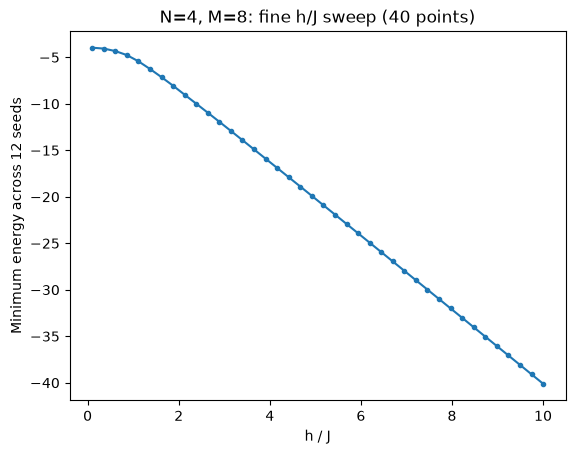

In [22]:
ratios_fine = np.linspace(0.1, 10.0, 40)
n_seeds_sweep = 12  # fewer seeds per ratio point to keep the fine grid affordable

min_energy_by_ratio = []
for ratio in ratios_fine:
    h = ratio * J_fixed_opt
    energies = [minimise_e_opt(seed, n_iterations=25, n_samples_steps=30, burn_in=25, h=h)[-1]
                for seed in range(n_seeds_sweep)]
    min_energy_by_ratio.append(np.min(energies))

fig = plt.figure()
plt.plot(ratios_fine, min_energy_by_ratio, marker='o', markersize=3, linestyle='-')
plt.xlabel('h / J')
plt.ylabel(f'Minimum energy across {n_seeds_sweep} seeds')
plt.title(f'N=4, M=8: fine h/J sweep ({len(ratios_fine)} points)')
plt.show()